In [38]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [23]:
file_path = "../data/raw/MuRun2010B.csv"
data = pd.read_csv(file_path)

In [24]:
data.head()

,Run,Event,Type1,E1,px1,py1,pz1,pt1,eta1,phi1,...,Type2,E2,px2,py2,pz2,pt2,eta2,phi2,Q2,M
0,146436,90830792,G,19.17120,3.817130,9.04323,-16.46730,9.81583,-1.289420,1.171390,...,T,5.43984,-0.362592,2.626990,-4.748490,2.65189,-1.345870,1.707960,1,2.73205
1,146436,90862225,G,12.94350,5.125790,-3.98369,-11.19730,6.49180,-1.313350,-0.660674,...,G,11.86360,4.789840,-6.262220,-8.864340,7.88403,-0.966622,-0.917841,1,3.10256
2,146436,90644850,G,12.39990,-0.849742,9.40110,8.04015,9.43943,0.772580,1.660940,...,G,8.55532,-4.851550,6.976960,-0.983229,8.49797,-0.115445,2.178410,-1,9.41149
3,146436,90678594,G,17.81320,-1.959590,2.80531,17.48110,3.42195,2.333500,2.180530,...,G,9.42174,4.365230,0.168017,8.347130,4.36846,1.403000,0.038471,1,7.74702
4,146436,90686690,G,7.95664,7.097000,-1.31646,3.34613,7.21806,0.448399,-0.183411,...,T,5.44467,-1.341760,1.386470,5.090250,1.92941,1.697380,2.339810,-1,8.67727


In [25]:
data.columns = data.columns.str.strip()
data.shape

(100000, 21)

In [26]:
data.columns.tolist()

['Run',
 'Event',
 'Type1',
 'E1',
 'px1',
 'py1',
 'pz1',
 'pt1',
 'eta1',
 'phi1',
 'Q1',
 'Type2',
 'E2',
 'px2',
 'py2',
 'pz2',
 'pt2',
 'eta2',
 'phi2',
 'Q2',
 'M']

In [27]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 21 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Run     100000 non-null  int64  
 1   Event   100000 non-null  int64  
 2   Type1   100000 non-null  object 
 3   E1      100000 non-null  float64
 4   px1     100000 non-null  float64
 5   py1     100000 non-null  float64
 6   pz1     100000 non-null  float64
 7   pt1     100000 non-null  float64
 8   eta1    100000 non-null  float64
 9   phi1    100000 non-null  float64
 10  Q1      100000 non-null  int64  
 11  Type2   100000 non-null  object 
 12  E2      100000 non-null  float64
 13  px2     100000 non-null  float64
 14  py2     100000 non-null  float64
 15  pz2     100000 non-null  float64
 16  pt2     100000 non-null  float64
 17  eta2    100000 non-null  float64
 18  phi2    100000 non-null  float64
 19  Q2      100000 non-null  int64  
 20  M       100000 non-null  float64
dtypes: float64(

In [28]:
data.isnull().sum()

Run      0
Event    0
Type1    0
E1       0
px1      0
py1      0
pz1      0
pt1      0
eta1     0
phi1     0
Q1       0
Type2    0
E2       0
px2      0
py2      0
pz2      0
pt2      0
eta2     0
phi2     0
Q2       0
M        0
dtype: int64

In [29]:
data["pt1_calculated"] = np.sqrt(
    data["px1"]**2 + data["py1"]**2)

In [30]:
data[["px1", "py1", "pt1", "pt1_calculated"]].head()

,px1,py1,pt1,pt1_calculated
0,3.817130,9.04323,9.81583,9.815829
1,5.125790,-3.98369,6.49180,6.491803
2,-0.849742,9.40110,9.43943,9.439425
3,-1.959590,2.80531,3.42195,3.421952
4,7.097000,-1.31646,7.21806,7.218066


In [31]:
pt1_difference = abs(data["pt1"] - data["pt1_calculated"])
pt1_difference.max()

0.0008109140447913887

In [32]:
E_total = data["E1"] + data["E2"]
px_total = data["px1"] + data["px2"]
py_total = data["py1"] + data["py2"]
pz_total = data["pz1"] + data["pz2"]

In [33]:
mass_squared = (
    E_total**2
    - px_total**2
    - py_total**2
    - pz_total**2)

In [34]:
data["M_calculated"] = np.sqrt(mass_squared)

In [35]:
data[["M", "M_calculated"]].head(10)

,M,M_calculated
0,2.73205,2.732339
1,3.10256,3.102325
2,9.41149,9.411457
3,7.74702,7.747046
4,8.67727,8.677264
5,2.30104,2.301203
6,8.38705,8.387112
7,4.14828,4.148005
8,3.13180,3.131834
9,28.36050,28.360428


In [36]:
mass_difference = abs(data["M"] - data["M_calculated"])
mass_difference.max()

2.2915458548166434

In [37]:
mass_difference.describe(
    percentiles=[0.50, 0.90, 0.95, 0.99, 0.999])

count    1.000000e+05
mean     2.599075e-04
std      9.353251e-03
min      1.347402e-10
50%      5.062255e-05
90%      4.486029e-04
95%      7.209885e-04
99%      1.659749e-03
99.9%    1.377911e-02
max      2.291546e+00
dtype: float64

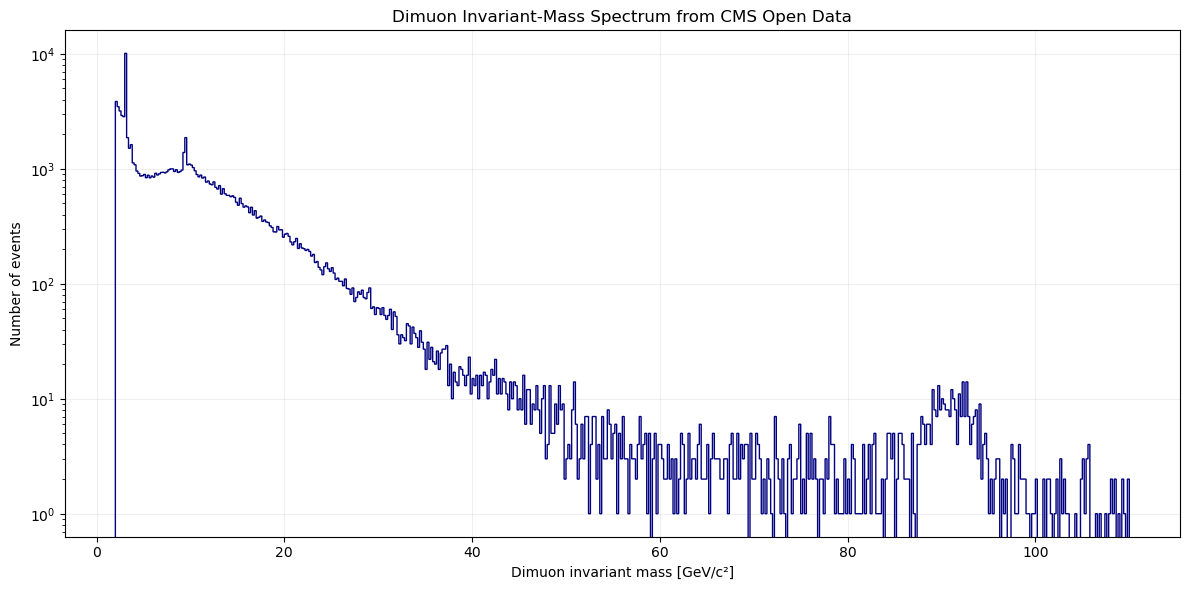

In [39]:
plt.figure(figsize=(12, 6))

plt.hist(
    data["M_calculated"],
    bins=540,
    range=(2, 110),
    histtype="step",
    color="navy")

plt.xlabel("Dimuon invariant mass [GeV/c²]")
plt.ylabel("Number of events")
plt.title("Dimuon Invariant-Mass Spectrum from CMS Open Data")

plt.yscale("log")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## Opposite-charge event selection

Neutral resonances such as the J/ψ, Υ and Z bosons can decay into a
positive muon and a negative muon. Therefore, opposite-charge muon pairs
are expected to contain the physical resonance signals, while same-charge
pairs can help represent background combinations.

In [40]:
opposite_charge = data[data["Q1"] * data["Q2"] == -1].copy()
same_charge = data[data["Q1"] * data["Q2"] == 1].copy()

print("Opposite-charge events:", len(opposite_charge))
print("Same-charge events:", len(same_charge))

Opposite-charge events: 63946
Same-charge events: 36054


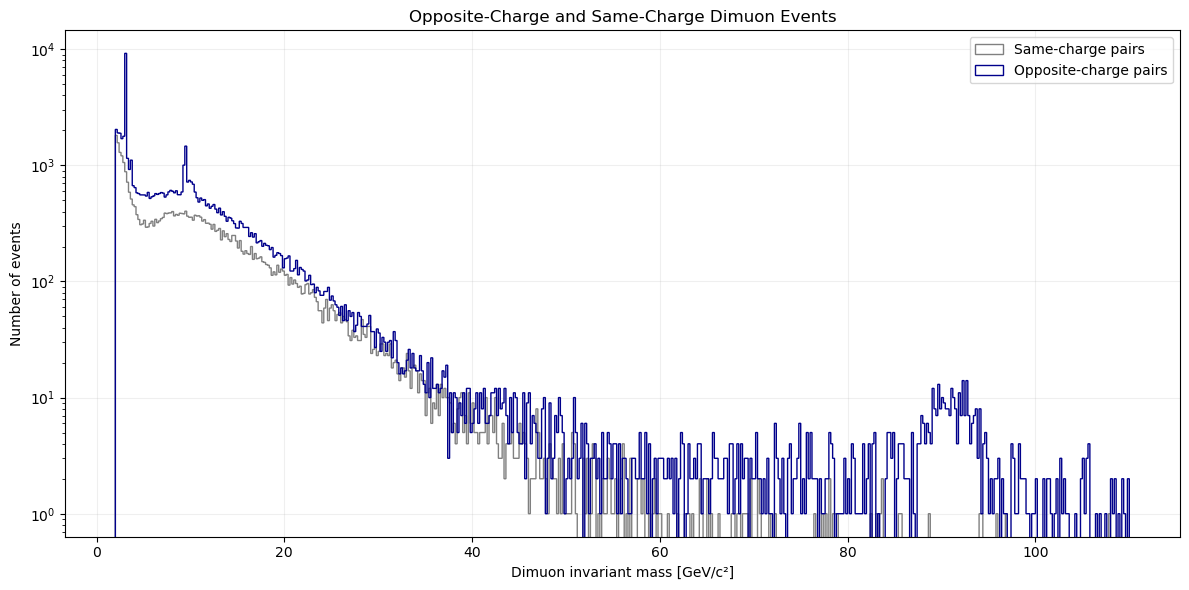

In [41]:
# Compare their mass distributions

plt.figure(figsize=(12, 6))

plt.hist(
    same_charge["M_calculated"],
    bins=540,
    range=(2, 110),
    histtype="step",
    color="gray",
    label="Same-charge pairs")

plt.hist(
    opposite_charge["M_calculated"],
    bins=540,
    range=(2, 110),
    histtype="step",
    color="darkblue",
    label="Opposite-charge pairs")

plt.xlabel("Dimuon invariant mass [GeV/c²]")
plt.ylabel("Number of events")
plt.title("Opposite-Charge and Same-Charge Dimuon Events")
plt.yscale("log")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## J/ψ resonance

The first prominent resonance appears near 3.1 GeV/c². We isolate this
region using opposite-charge dimuon events and estimate the particle's
mass from the position of the histogram peak.

In [42]:
jpsi_region = opposite_charge[
    (opposite_charge["M_calculated"] >= 2.7)
    & (opposite_charge["M_calculated"] <= 3.5)
].copy()

print("Events in J/ψ region:", len(jpsi_region))

Events in J/ψ region: 13444


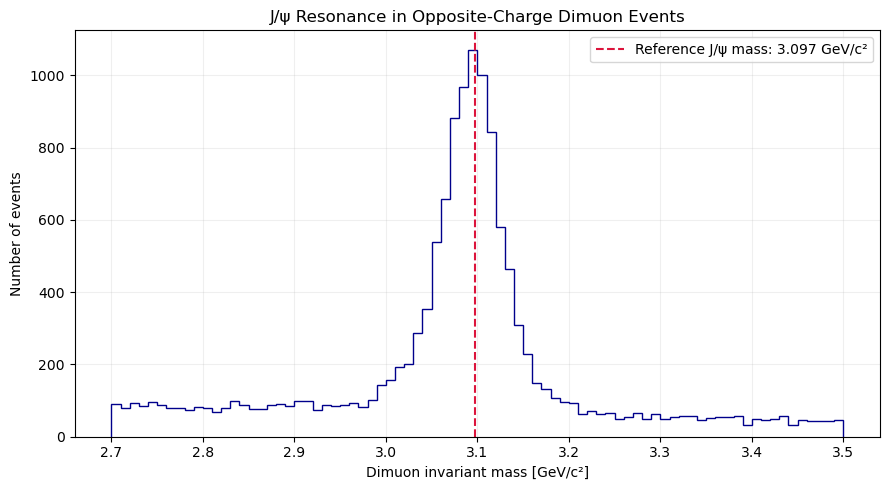

In [43]:
plt.figure(figsize=(9, 5))

plt.hist(
    jpsi_region["M_calculated"],
    bins=80,
    range=(2.7, 3.5),
    histtype="step",
    color="darkblue")


plt.axvline(
    3.097,
    color="crimson",
    linestyle="--",
    label="Reference J/ψ mass: 3.097 GeV/c²")


plt.xlabel("Dimuon invariant mass [GeV/c²]")
plt.ylabel("Number of events")
plt.title("J/ψ Resonance in Opposite-Charge Dimuon Events")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

In [44]:
counts, bin_edges = np.histogram(
    jpsi_region["M_calculated"],
    bins=80,
    range=(2.7, 3.5)
)

peak_index = np.argmax(counts)

jpsi_peak_mass = (
    bin_edges[peak_index] + bin_edges[peak_index + 1]
) / 2

print("Estimated J/ψ mass:", jpsi_peak_mass, "GeV/c²")

Estimated J/ψ mass: 3.095 GeV/c²


## Υ resonance family

The mass region between 8.5 and 11 GeV/c² contains bottomonium states
known as Υ(1S), Υ(2S), and Υ(3S). These states can decay into an
opposite-charge muon pair.

In [45]:
upsilon_region = opposite_charge[
    (opposite_charge["M_calculated"] >= 8.5)
    & (opposite_charge["M_calculated"] <= 11.0)
].copy()

print("Events in Υ region:", len(upsilon_region))

Events in Υ region: 8948


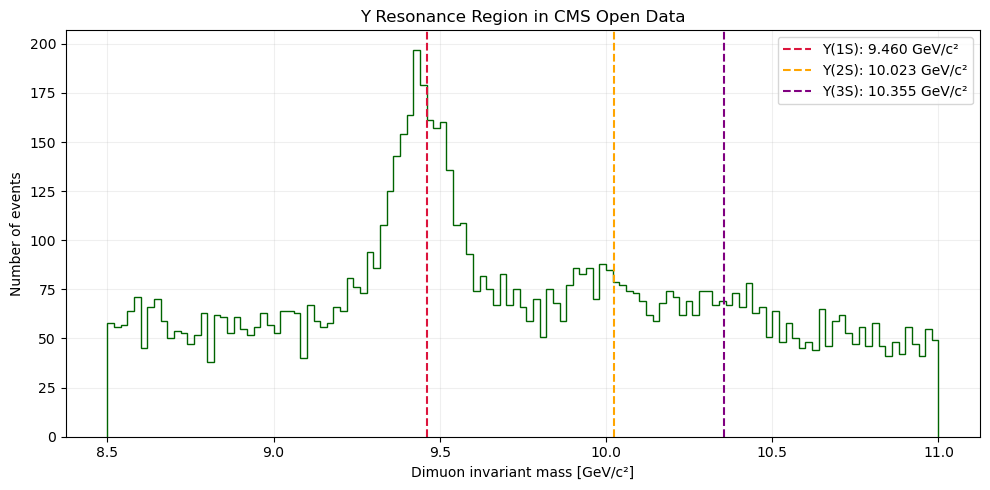

In [46]:
plt.figure(figsize=(10, 5))

plt.hist(
    upsilon_region["M_calculated"],
    bins=125,
    range=(8.5, 11.0),
    histtype="step",
    color="darkgreen")

plt.axvline(
    9.460,
    color="crimson",
    linestyle="--",
    label="Υ(1S): 9.460 GeV/c²")

plt.axvline(
    10.023,
    color="orange",
    linestyle="--",
    label="Υ(2S): 10.023 GeV/c²")

plt.axvline(
    10.355,
    color="purple",
    linestyle="--",
    label="Υ(3S): 10.355 GeV/c²")

plt.xlabel("Dimuon invariant mass [GeV/c²]")
plt.ylabel("Number of events")
plt.title("Υ Resonance Region in CMS Open Data")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

In [47]:
counts, bin_edges = np.histogram(
    upsilon_region["M_calculated"],
    bins=125,
    range=(8.5, 11.0)
)

peak_index = np.argmax(counts)

upsilon_peak_mass = (
    bin_edges[peak_index] + bin_edges[peak_index + 1]
) / 2

print("Estimated Υ(1S) mass:", upsilon_peak_mass, "GeV/c²")

Estimated Υ(1S) mass: 9.43 GeV/c²


## Z-boson resonance

The high-mass region contains the Z-boson resonance. The number of events
is much smaller than in the J/ψ region, so wider histogram bins are used
to reduce statistical fluctuations.

In [48]:
z_region = opposite_charge[
    (opposite_charge["M_calculated"] >= 75)
    & (opposite_charge["M_calculated"] <= 105)
].copy()

print("Events in Z region:", len(z_region))

Events in Z region: 465


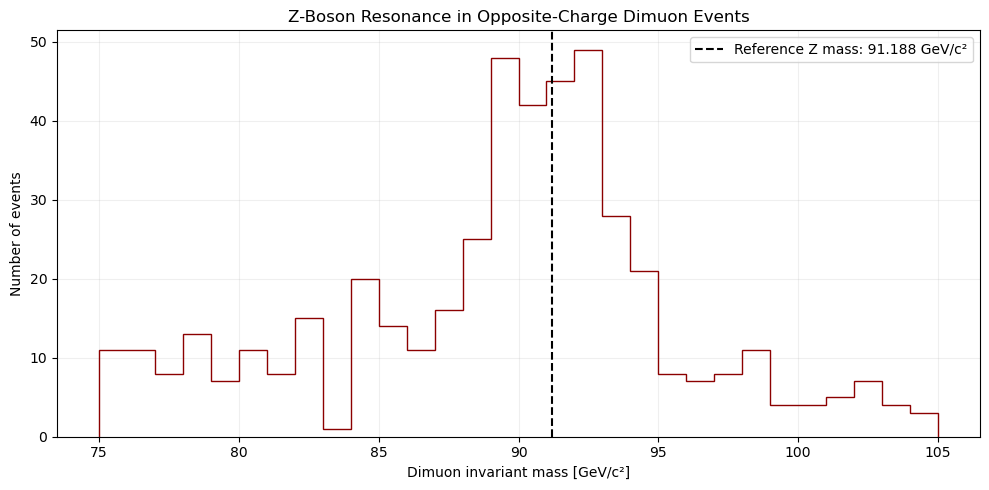

In [49]:
plt.figure(figsize=(10, 5))

plt.hist(
    z_region["M_calculated"],
    bins=30,
    range=(75, 105),
    histtype="step",
    color="darkred")

plt.axvline(
    91.188,
    color="black",
    linestyle="--",
    label="Reference Z mass: 91.188 GeV/c²")

plt.xlabel("Dimuon invariant mass [GeV/c²]")
plt.ylabel("Number of events")
plt.title("Z-Boson Resonance in Opposite-Charge Dimuon Events")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

In [50]:
z_peak_region = opposite_charge[
    (opposite_charge["M_calculated"] >= 85)
    & (opposite_charge["M_calculated"] <= 97)
].copy()

counts, bin_edges = np.histogram(
    z_peak_region["M_calculated"],
    bins=30,
    range=(85, 97)
)

peak_index = np.argmax(counts)

z_peak_mass = (
    bin_edges[peak_index] + bin_edges[peak_index + 1]
) / 2

print("Estimated Z-boson mass:", z_peak_mass, "GeV/c²")

Estimated Z-boson mass: 91.2 GeV/c²


## Summary of reconstructed particle masses

The histogram peak positions are compared with established reference
masses. These are approximate, bin-dependent estimates rather than
precision measurements.

In [51]:
results = pd.DataFrame({
    "Particle": ["J/ψ", "Υ(1S)", "Z boson"],
    "Estimated mass [GeV/c²]": [
        jpsi_peak_mass,
        upsilon_peak_mass,
        z_peak_mass
    ],
    "Reference mass [GeV/c²]": [
        3.0969,
        9.4603,
        91.1876
    ]
})

results["Absolute difference [GeV/c²]"] = abs(
    results["Estimated mass [GeV/c²]"]
    - results["Reference mass [GeV/c²]"]
)

results["Relative difference [%]"] = (
    results["Absolute difference [GeV/c²]"]
    / results["Reference mass [GeV/c²]"]
) * 100

results.round(4)

,Particle,Estimated mass [GeV/c²],Reference mass [GeV/c²],Absolute difference [GeV/c²],Relative difference [%]
0,J/ψ,3.095,3.0969,0.0019,0.0614
1,Υ(1S),9.430,9.4603,0.0303,0.3203
2,Z boson,91.200,91.1876,0.0124,0.0136


## Muon transverse-momentum comparison

The transverse-momentum distributions of muons from the J/ψ and Z
regions are compared. Since the Z boson is much heavier, its decay
generally produces muons with considerably higher transverse momentum.

In [52]:
jpsi_pt = pd.concat(
    [jpsi_region["pt1"], jpsi_region["pt2"]],
    ignore_index=True
)

z_pt = pd.concat(
    [z_peak_region["pt1"], z_peak_region["pt2"]],
    ignore_index=True
)

print("Median J/ψ-region muon pT:", jpsi_pt.median(), "GeV/c")
print("Median Z-region muon pT:", z_pt.median(), "GeV/c")

Median J/ψ-region muon pT: 4.585025 GeV/c
Median Z-region muon pT: 41.41165 GeV/c


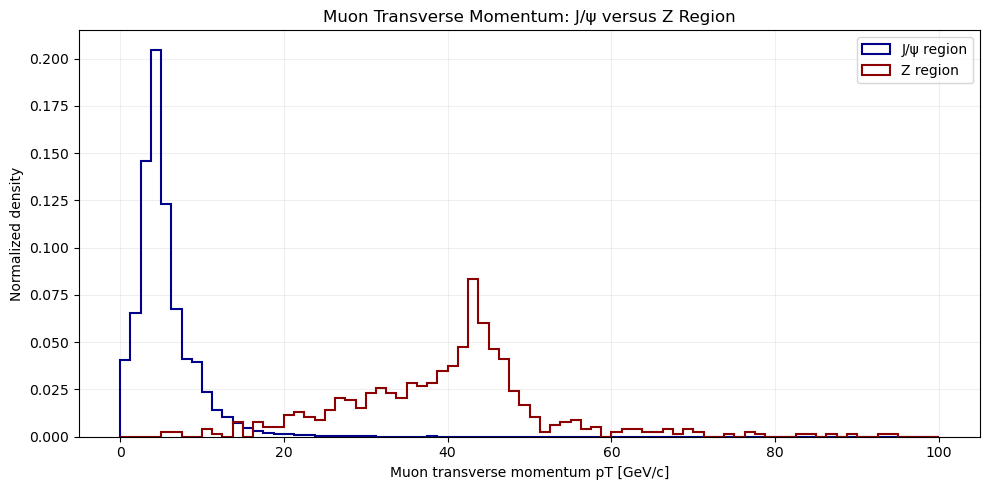

In [53]:
plt.figure(figsize=(10, 5))

plt.hist(
    jpsi_pt,
    bins=80,
    range=(0, 100),
    density=True,
    histtype="step",
    linewidth=1.5,
    color="darkblue",
    label="J/ψ region")

plt.hist(
    z_pt,
    bins=80,
    range=(0, 100),
    density=True,
    histtype="step",
    linewidth=1.5,
    color="darkred",
    label="Z region")

plt.xlabel("Muon transverse momentum pT [GeV/c]")
plt.ylabel("Normalized density")
plt.title("Muon Transverse Momentum: J/ψ versus Z Region")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()